# Extra experiments: PCA of enriched features
Not part of the main result. Setup cells (data loading and cleaning) come first, then the PCA block. Run top to bottom.

In [105]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [106]:
import os
API_KEY = os.environ.get("GEMINI_API_KEY")

In [107]:
from pathlib import Path
DATA_PATH = Path("Clean_dataset.xlsx")
df = pd.read_excel(DATA_PATH)
df.loc[df['Reference'] == 'DC20-3', 'Qmax (kN)'] = 9220.0

In [108]:
df

,Reference,Location,GW_depth,Depth(m),Soil Profile,Soil Property,UCSC Classification,Gravel,Sand,Clay,...,L1(smax)(mm),L2(Qmax)(kn),L2(smax)(mm),Terzhagi & Peck(Qmax)(kn),van Der Veen(Qmax)(kn),van Der Veen(smax)(mm),Fuller & Hoy(Qmax)(kn),Fuller & Hoy(smax)(mm),Chin(Qmax)(kn),Chin(smax)(mm)
0,DC1-1,"Glasgow, UK",6,17.5,Silty fine & medium sand,DC1-1,SW-SM,0,100.0,0.0,...,1.70,2078,36.70,1634,1750,28.9,2079,55.2,2500,>68.7
1,DC1-2,"Glasgow, UK",6,17.5,Silty fine & medium sand,DC1-2,SW-SM,0,100.0,0.0,...,1.80,2344,35.80,2000,2000,26.8,2343,40.9,3333,>51.5
2,DC1-3,"Glasgow, UK",6,16.0,Silty fine & medium sand,DC1-3,SW-SM,0,100.0,0.0,...,2.90,1759,36.30,1552,2000,54.1,2068,60,2500,>65.4
3,DC1-4,"Glasgow, UK",6,20.0,Silty fine & medium sand,DC1-4,SW-SM,0,100.0,0.0,...,2.90,2618,43.70,1759,2700,66.8,2628,61.7,3333,>69.7
4,DC1-5,"Glasgow, UK",6,17.5,Silty fine & medium sand,DC1-5,SW-SM,0,100.0,0.0,...,1.70,2483,40.80,2117,2250,29,3103,59.3,3333,>65.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138,UC38,"Houston-Gulf, Texas, USA",1.4,18.9,Stiff Beaumont clay formation,NaN,NaN,0,5.0,95.0,...,1.80,1840,12.40,2040,1900,15.9,2040,25,2500,>25.4
139,UC39,"Bangkok, Thailand",1,57.5,"Soft, hard clay and dense sand",NaN,NaN,0,23.0,77.0,...,5.00,27500,31.95,25784,23500,19.26,27050,30.01,37074,38.5
140,UC40,Taiwan,NR,33.4,"Sand, clay and gravel",NaN,NaN,28,14.0,58.0,...,9.27,17000,30.14,15833,18000,35.08,24800,130,28091,130
141,UC41,Taiwan,NR,55.9,"Sand, clay and debris",NaN,NaN,18,5.0,77.0,...,8.97,41433,40.50,32149,53000,40.5,53793,40.5,65116,40.5


In [109]:
df.shape

(143, 42)

In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 42 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Reference                             143 non-null    str    
 1   Location                              143 non-null    str    
 2   GW_depth                              143 non-null    object 
 3   Depth(m)                              143 non-null    float64
 4   Soil Profile                          143 non-null    str    
 5   Soil Property                         62 non-null     str    
 6   UCSC Classification                   103 non-null    str    
 7   Gravel                                143 non-null    int64  
 8   Sand                                  143 non-null    float64
 9   Clay                                  143 non-null    float64
 10  Moisture Content (%)                  12 non-null     object 
 11  Unit Weight,γt (kN/m3)        

In [111]:
#Remove leading and trailing whitespace from all text columns to standardize categories and prevent matching errors
str_cols = df.select_dtypes(include=['object', 'string']).columns
for col in str_cols:
    df[col] = df[col].where(df[col].isna(), df[col].astype(str).str.strip())

In [112]:
print('UCSC Classification list:',df['UCSC Classification'].unique())
print('UCSC Classification has nun values:',df['UCSC Classification'].isnull().sum())
print('Soil Profile list:',df['Soil Profile'].unique())
print('Soil Profile has nan values',df['Soil Profile'].isnull().sum())

UCSC Classification list: <ArrowStringArray>
[   'SW-SM',    'SM-SC',        nan,       'GM',    'SM/ML',       'SM',
       'SP',       'SC',       'MH',       'SW',    'SC-SM',    'CL-CH',
       'CL', 'SM-SC/CL',       'CH',    'CH/OH',       'ML',       'OH']
Length: 18, dtype: str
UCSC Classification has nun values: 40
Soil Profile list: <ArrowStringArray>
[                             'Silty fine & medium sand',
                                 'Clayey silt/fine sand',
                   'Outwash sand & tidal marsh deposits',
                                  '85% sand, 15% gravel',
                                  'Stratified sand/peat',
                                 'Silty & gravelly sand',
                                            'Silty sand',
                                       'Silty fine sand',
                        'Loose fine grey silt with sand',
                                    'Poorly graded sand',
                          'Medium dense silty fine sand'

In [113]:
#Now we will classify the soil using UCSC Classification(which have 39 nan values), and soil profile . 
#We will try to process those values too by using sand, gravel and clay percentage.

#1st: Clean the UCSC Classification
df['UCSC Classification']=df['UCSC Classification'].str.strip().replace('',np.nan)


In [114]:
print('UCSC Classification has nun values:',df['UCSC Classification'].isnull().sum())

UCSC Classification has nun values: 40


**Soil Classification and Grain Size Distribution**

In [115]:
#2nd:Build Soil Class using UCSC Classification first, the think about the 40 Nans
ucsc=df['UCSC Classification']
profile=df['Soil Profile'].str.lower()

#3rd:Grain Classification of UCSC(Technical Knowledge) and for avoiding error, normalize any values
coarse_ucsc={'SW','SP','SM','SC','SW-SM','SC-SM','SM-SC','GM','GW','GP','GC'}
fine_ucsc={'CL', 'CH', 'ML', 'MH', 'OH', 'OL', 'CL-CH', 'CH/OH', 'CL-ML'}
mixed_ucsc = {'SM-SC/CL', 'SM/ML'}

for col in ['Gravel', 'Sand', 'Clay']:
  df[col] = (df[col].astype(str).str.extract(r'(\d+\.?\d*)', expand=False).astype(float))

#4th:preprocessing null percentages of grain,Sand and Clay 
has_grain_information=df[['Gravel','Sand','Clay']].notna().any(axis=1)
coarse_percent=df['Gravel'].fillna(0)+df['Sand'].fillna(0)
fine_percent=df['Clay'].fillna(0)

#5th:Classification of the null values of UCSC classification through soil profile
is_rock=profile.str.contains(r'rock|limestone|shale|cemented|siltstone|mudstone',regex=True)
has_coarse_text=profile.str.contains(r'sand|gravel|granular',regex=True)
has_fine_text=profile.str.contains(r'clay|silt|loam',regex=True)

#6th:Now set conditions for soil_class
class_conditions=[
    #Condition_1:Direct Classification through UCSC Classification
    ucsc.isin(coarse_ucsc),
    ucsc.isin(fine_ucsc),
    ucsc.isin(mixed_ucsc),

    #Condition_2:only when UCSC Classification is missing (40 piles)
    ucsc.isna() & is_rock,
    ucsc.isna() & has_grain_information & (coarse_percent >= 70),
    ucsc.isna() & has_grain_information & (fine_percent >= 70),
    ucsc.isna() & has_grain_information & (fine_percent > 30) & (fine_percent < 70),
    ucsc.isna() & ~has_grain_information & has_coarse_text & has_fine_text,
    ucsc.isna() & ~has_grain_information & has_coarse_text & ~has_fine_text,
    ucsc.isna() & ~has_grain_information & has_fine_text & ~has_coarse_text,
]

#7th:Naming the Soil Samples
choices=[
    'Coarse-grained (Sand/Gravel)',
    'Fine-grained (Clay/Silt)',
    'Mixed / Borderline',
    'Cemented / Rock',
    'Coarse-grained (Sand/Gravel)',
    'Fine-grained (Clay/Silt)',
    'Mixed / Borderline',
    'Mixed / Borderline',
    'Coarse-grained (Sand/Gravel)',
    'Fine-grained (Clay/Silt)',
]

df['soil_class'] = np.select(class_conditions, choices, default='Unknown')


In [116]:
# 8th: Build gradation column (reusing `ucsc` and `profile`)
well_graded_ucsc = {'SW', 'SW-SM', 'SW-SC', 'GW', 'GW-GM', 'GW-GC'}
poorly_graded_ucsc = {'SP', 'SP-SM', 'SP-SC', 'GP', 'GP-GM', 'GP-GC'}

#9th:Now set conditions for soil_gradation
gradation_conditions = [

    #By UCSC
    ucsc.isin(well_graded_ucsc),
    ucsc.isin(poorly_graded_ucsc),

    #When UCSC or gradation is missing
    ucsc.isna() & profile.str.contains(r'well[- ]graded', regex=True),
    ucsc.isna() & profile.str.contains(r'poorly[- ]graded', regex=True),
]

gradation_choices = [
    'Well-graded',
    'Poorly-graded',
    'Well-graded',
    'Poorly-graded',
]

df['gradation'] = np.select(
    gradation_conditions, gradation_choices, default='Not specified'
)

In [117]:
df['gradation'].value_counts(dropna=False)

gradation
Not specified    120
Well-graded       22
Poorly-graded      1
Name: count, dtype: int64

In [118]:
df['soil_class'].value_counts(dropna=False)

soil_class
Fine-grained (Clay/Silt)        70
Coarse-grained (Sand/Gravel)    58
Mixed / Borderline               9
Cemented / Rock                  6
Name: count, dtype: int64

In [119]:
#Making site as a category for grouping, as one site represents same type of soil.
df['site'] = df['Reference'].str.split('-').str[0].str.strip().astype(str)

In [120]:
#Dropping features who have too many Nan Values
df=df.drop(columns=['Chin(smax)(mm)','Moisture Content (%)'])

**Standardization of Units**

In [121]:
import re

def parse_with_units(val, target_unit):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if s == "" or s.lower() == "nan":
        return np.nan

    # At first, extract numeric value 
    match = re.search(r'[-+]?\d*\.?\d+', s)
    if not match:
        return np.nan
    num = float(match.group())
    s_lower = s.lower()

    # Standardize length / depth to meters (m)
    if target_unit == 'm':
        if re.search(r'\bmm\b', s_lower):
            return num / 1000.0
        elif re.search(r'\bcm\b', s_lower):
            return num / 100.0
        elif re.search(r'\b(ft|feet)\b', s_lower) or "'" in s_lower:
            return num * 0.3048
        elif re.search(r'\b(in|inch|inches)\b', s_lower) or '"' in s_lower:
            return num * 0.0254

    # Standardize settlement to millimeters (mm)
    elif target_unit == 'mm':
        if re.search(r'\bcm\b', s_lower):
            return num * 10.0
        elif re.search(r'\b(in|inch|inches)\b', s_lower) or '"' in s_lower:
            return num * 25.4
        elif re.search(r'\bm\b', s_lower):  # standalone 'm', not 'mm'
            return num * 1000.0

    # Standardize stress / undrained shear strength to kPa
    elif target_unit == 'kPa':
        if re.search(r'\bmpa\b', s_lower):
            return num * 1000.0
        elif re.search(r'\bpa\b', s_lower):
            return num / 1000.0
        elif re.search(r'\btsf\b', s_lower):
            return num * 95.76
        elif re.search(r'\bpsf\b', s_lower):
            return num * 0.04788
        elif 'kg/cm2' in s_lower or 'kgf/cm2' in s_lower:
            return num * 98.0665

    # Standardize load / capacity to kN
    elif target_unit == 'kN':
        if re.search(r'\bmn\b', s_lower):
            return num * 1000.0
        elif re.search(r'\b(ton|tons|tf)\b', s_lower):
            return num * 9.80665
        elif re.search(r'\b(kip|kips)\b', s_lower):
            return num * 4.44822
        elif re.search(r'\b(lb|lbs)\b', s_lower):
            return num * 0.00444822

    # Standardize unit weight to kN/m3
    elif target_unit == 'kN/m3':
        if 'pcf' in s_lower or 'lb/ft3' in s_lower:
            return num * 0.157087
        elif 'g/cm3' in s_lower or 't/m3' in s_lower or 'mg/m3' in s_lower:
            return num * 9.80665

    return num

# Map every column in your sheet to its target standard unit
unit_map = {
    'GW_depth': 'm',
    'Undrained Shear Strength(su (kPa))': 'kPa',
    'Slope Tangent(smax)(mm)': 'mm',
    '4% B(smax)(mm)': 'mm',
    'van Der Veen(smax)(mm)': 'mm',
    'Fuller & Hoy(smax)(mm)': 'mm',
}

# Also catch geometry, unit weight, and any other Qmax/smax columns if present in df
for col in df.columns:
    if col in ['B', 'L', 'B (m)', 'L (m)']:
        unit_map[col] = 'm'
    elif 'kN/m3' in col or 'γ' in col:
        unit_map[col] = 'kN/m3'
    elif '(Qmax)' in col or col == 'Qmax (kN)':
        unit_map[col] = 'kN'
    elif '(smax)' in col or col == 'smax (mm)':
        unit_map[col] = 'mm'

# Apply unit conversion across all mapped columns
for col, unit in unit_map.items():
    if col in df.columns:
        df[col] = df[col].apply(lambda x: parse_with_units(x, unit))

# Unitless columns (SPT_N, Friction Angle): it feels safe to strip text
unitless_cols = ['SPT_N', 'Friction Angle(ϕ (deg))']
for col in unitless_cols:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.extract(r'([-+]?\d*\.?\d+)', expand=False)
            .astype(float)
        )

In [122]:
#Chech if there is any feature left as obejct 
obj_cols = [c for c in df.columns if df[c].dtype == 'object']
len(obj_cols)
print(obj_cols)

[]


In [123]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 43 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Reference                             143 non-null    str    
 1   Location                              143 non-null    str    
 2   GW_depth                              109 non-null    float64
 3   Depth(m)                              143 non-null    float64
 4   Soil Profile                          143 non-null    str    
 5   Soil Property                         62 non-null     str    
 6   UCSC Classification                   103 non-null    str    
 7   Gravel                                143 non-null    float64
 8   Sand                                  143 non-null    float64
 9   Clay                                  143 non-null    float64
 10  Unit Weight,γt (kN/m3)                57 non-null     float64
 11  Relative Density,Dr (%)       

In [124]:
df['Constr']=df['Constr'].replace('-c',np.nan).fillna('Unknown')

In [125]:
df['Location'] = df['Location'].replace({'Thailand, Bangkok': 'Bangkok, Thailand'})

In [126]:
#slederness of pile
df['L_B'] = df['L'] / df['B']

In [127]:
df['log(Qmax)'] = np.log(df['Qmax (kN)'])

**Extracting the image of soil Properties and using them to extend our information by using AI**

In [128]:
print("Exact column names:", df.columns.tolist())

# Find any column that contains 'drive.google.com' as plain text
link_cols = [c for c in df.columns if df[c].astype(str).str.contains("drive.google.com", na=False).any()]
print("Columns with Drive URLs:", link_cols)

Exact column names: ['Reference', 'Location', 'GW_depth', 'Depth(m)', 'Soil Profile', 'Soil Property', 'UCSC Classification', 'Gravel', 'Sand', 'Clay', 'Unit Weight,γt (kN/m3)', 'Relative Density,Dr (%)', "Vertical Effective Stress(σv' (kPa))", 'Friction Angle(ϕ (deg))', 'Undrained Shear Strength(su (kPa))', 'SPT_N', 'Constr', 'Pile Construction tool', 'L', 'B', 'Load Direction', 'Static Load Test Procedure', 'Qmax (kN)', 'smax (mm)', 'Slope Tangent(Qmax)(kn)', 'Slope Tangent(smax)(mm)', 'Dee Beer(Qmax)(kn)', 'Dee Beer(smax)(mm)', '4% B(Qmax)(kn)', '4% B(smax)(mm)', 'L1(Qmax)(kn)', 'L1(smax)(mm)', 'L2(Qmax)(kn)', 'L2(smax)(mm)', 'Terzhagi & Peck(Qmax)(kn)', 'van Der Veen(Qmax)(kn)', 'van Der Veen(smax)(mm)', 'Fuller & Hoy(Qmax)(kn)', 'Fuller & Hoy(smax)(mm)', 'Chin(Qmax)(kn)', 'soil_class', 'gradation', 'site', 'L_B', 'log(Qmax)']
Columns with Drive URLs: []


In [129]:
import openpyxl

# 1. Set Excel filename and sheet name
EXCEL_PATH = DATA_PATH
SHEET_NAME = "Sheet1"
TARGET_COL_NAME = "Soil Property"

# 2. Load the workbook with openpyxl (must NOT use read_only=True so hyperlinks load)
wb = openpyxl.load_workbook(EXCEL_PATH, data_only=True)
ws = wb[SHEET_NAME]

# 3. Locate the target column directly in Row 1
col_idx = next(
    (
        c for c in range(1, ws.max_column + 1)
        if isinstance(ws.cell(row=1, column=c).value, str)
        and ws.cell(row=1, column=c).value.strip().lower() == TARGET_COL_NAME.lower()
    ),
    None,
)

if col_idx is None:
    raise ValueError(f"Could not find column '{TARGET_COL_NAME}' in Row 1 of '{SHEET_NAME}'.")

# 4. Extract all embedded hyperlinks from Row 2 onward (matching df rows)
row_urls = [
    ws.cell(row=r, column=col_idx).hyperlink.target
    if ws.cell(row=r, column=col_idx).hyperlink
    else None
    for r in range(2, len(df) + 2)
]

df["Extracted_Drive_URL"] = row_urls

valid_count = df["Extracted_Drive_URL"].notna().sum()
print(f"Found '{TARGET_COL_NAME}' in Row 1, Column {col_idx}.")
print(f"Successfully extracted {valid_count} embedded Drive URLs!")
print(df[[TARGET_COL_NAME, "Extracted_Drive_URL"]].dropna().head(10))

Found 'Soil Property' in Row 1, Column 6.
Successfully extracted 60 embedded Drive URLs!
   Soil Property                                Extracted_Drive_URL
0          DC1-1  https://drive.google.com/open?id=1yE-wi8zvgWXk...
1          DC1-2  https://drive.google.com/open?id=1yE-wi8zvgWXk...
2          DC1-3  https://drive.google.com/open?id=1yE-wi8zvgWXk...
3          DC1-4  https://drive.google.com/open?id=1yE-wi8zvgWXk...
4          DC1-5  https://drive.google.com/open?id=1yE-wi8zvgWXk...
5            DC2  https://drive.google.com/open?id=1W3Hu75Oxu_xn...
6            DC3  https://drive.google.com/open?id=1BCp0K5WLyQHB...
7            DC4  https://drive.google.com/open?id=1cFX-FF-c0mqr...
9            DC6  https://drive.google.com/open?id=11U4LUuD3Ds0z...
10           DC7  https://drive.google.com/open?id=1Lw5MtXvPkFV5...


In [130]:
print(df.columns.tolist())

['Reference', 'Location', 'GW_depth', 'Depth(m)', 'Soil Profile', 'Soil Property', 'UCSC Classification', 'Gravel', 'Sand', 'Clay', 'Unit Weight,γt (kN/m3)', 'Relative Density,Dr (%)', "Vertical Effective Stress(σv' (kPa))", 'Friction Angle(ϕ (deg))', 'Undrained Shear Strength(su (kPa))', 'SPT_N', 'Constr', 'Pile Construction tool', 'L', 'B', 'Load Direction', 'Static Load Test Procedure', 'Qmax (kN)', 'smax (mm)', 'Slope Tangent(Qmax)(kn)', 'Slope Tangent(smax)(mm)', 'Dee Beer(Qmax)(kn)', 'Dee Beer(smax)(mm)', '4% B(Qmax)(kn)', '4% B(smax)(mm)', 'L1(Qmax)(kn)', 'L1(smax)(mm)', 'L2(Qmax)(kn)', 'L2(smax)(mm)', 'Terzhagi & Peck(Qmax)(kn)', 'van Der Veen(Qmax)(kn)', 'van Der Veen(smax)(mm)', 'Fuller & Hoy(Qmax)(kn)', 'Fuller & Hoy(smax)(mm)', 'Chin(Qmax)(kn)', 'soil_class', 'gradation', 'site', 'L_B', 'log(Qmax)', 'Extracted_Drive_URL']


In [131]:
# Set to True only if you want to re-download the borehole figures from Google Drive.
# Not needed to run the notebook: the extracted results are already saved in extracted_json/.
DOWNLOAD_IMAGES = False

# 1. Folder for the images (created even when not downloading, so later cells do not fail)
IMAGE_DIR = "downloaded_graphs"
os.makedirs(IMAGE_DIR, exist_ok=True)

# 2. Function to pull the ID out of a Google Drive link
def extract_drive_id(url):
    if not isinstance(url, str):
        return None
    match = re.search(r"(?:/file/d/|id=|/d/)([a-zA-Z0-9_-]+)", url)
    return match.group(1) if match else None

# 3. Create the '_file_id' column in the dataframe (later cells need it, so this always runs)
df["_file_id"] = df["Extracted_Drive_URL"].apply(extract_drive_id)

# 4. Download each unique image only if asked
unique_ids = df["_file_id"].dropna().unique()

if DOWNLOAD_IMAGES:
    import requests
    from tqdm import tqdm

    print(f"Downloading {len(unique_ids)} unique images...")
    for file_id in tqdm(unique_ids):
        save_path = os.path.join(IMAGE_DIR, f"{file_id}.png")
        if not os.path.exists(save_path):
            url = f"https://drive.google.com/uc?export=download&id={file_id}"
            r = requests.get(url)
            if r.status_code == 200:
                with open(save_path, "wb") as f:
                    f.write(r.content)
    print("Download complete!")
else:
    print(f"Download skipped. {len(unique_ids)} figure links found, results are read from extracted_json/.")

Download skipped. 47 figure links found, results are read from extracted_json/.


In [132]:
import os

IMAGE_DIR = "downloaded_graphs"
files = os.listdir(IMAGE_DIR)
small_files = [f for f in files if os.path.getsize(os.path.join(IMAGE_DIR, f)) < 5000]
print(f"Total files: {len(files)} | Files under 5KB (check if HTML/corrupt): {len(small_files)}")

Total files: 47 | Files under 5KB (check if HTML/corrupt): 0


In [133]:
# Find all rows in df whose _file_id appears more than once
dup_mask = df["_file_id"].notna() & df.duplicated(subset=["_file_id"], keep=False)

cols_to_show = [c for c in ["site", "Location", "L", "B", "Qmax", "_file_id", "Extracted_Drive_URL"] if c in df.columns]

print(f"Total rows sharing a Drive image: {dup_mask.sum()} rows across {df.loc[dup_mask, '_file_id'].nunique()} shared images\n")
display(df.loc[dup_mask, cols_to_show].sort_values("_file_id"))

Total rows sharing a Drive image: 19 rows across 6 shared images



,site,Location,L,B,_file_id,Extracted_Drive_URL
61,UC1,"Saskatoon, Saskatchewan, Canada",5.5,0.61,1MOIbWVvMLc2y05-XLMy_TaRT358W1HfA,https://drive.google.com/open?id=1MOIbWVvMLc2y...
62,UC1,"Saskatoon, Saskatchewan, Canada",8.2,0.61,1MOIbWVvMLc2y05-XLMy_TaRT358W1HfA,https://drive.google.com/open?id=1MOIbWVvMLc2y...
87,UC15,"Allegheny County, Pennsylvania, USA",5.2,0.46,1UwQxMxAxxdYfc_-YeHDE_ktLkmsaZqOU,https://drive.google.com/open?id=1UwQxMxAxxdYf...
88,UC15,"Allegheny County, Pennsylvania, USA",5.2,0.76,1UwQxMxAxxdYfc_-YeHDE_ktLkmsaZqOU,https://drive.google.com/open?id=1UwQxMxAxxdYf...
89,UC15,"Allegheny County, Pennsylvania, USA",4.3,0.76,1UwQxMxAxxdYfc_-YeHDE_ktLkmsaZqOU,https://drive.google.com/open?id=1UwQxMxAxxdYf...
68,UC4,"Bangkok, Thailand",25.8,1.00,1Vdmo9BOTC5joBgFTubhrp8rn-nuB1r-1,https://drive.google.com/open?id=1Vdmo9BOTC5jo...
69,UC4,"Bangkok, Thailand",26.7,1.00,1Vdmo9BOTC5joBgFTubhrp8rn-nuB1r-1,https://drive.google.com/open?id=1Vdmo9BOTC5jo...
70,UC4,"Bangkok, Thailand",25.5,1.20,1Vdmo9BOTC5joBgFTubhrp8rn-nuB1r-1,https://drive.google.com/open?id=1Vdmo9BOTC5jo...
64,UC3,"College Station, Texas, USA",1.8,0.18,1iR43obfM289FRY1T_inveHzIOFPY85CC,https://drive.google.com/open?id=1iR43obfM289F...
65,UC3,"College Station, Texas, USA",3.1,0.18,1iR43obfM289FRY1T_inveHzIOFPY85CC,https://drive.google.com/open?id=1iR43obfM289F...


downloaded_graphs\10E6N7nQ0qEvwv3N4726qg9VcUFQX5zVy.png


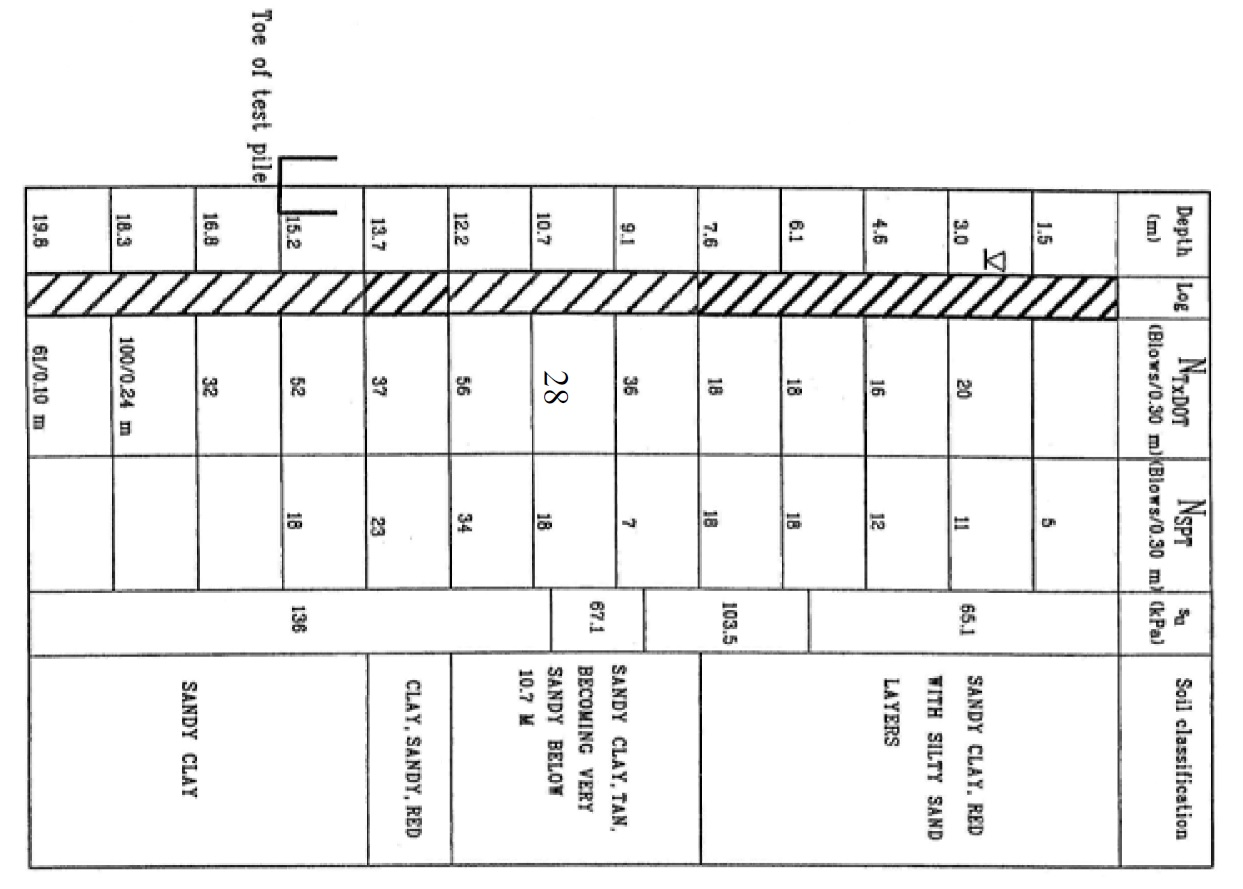

downloaded_graphs\11U4LUuD3Ds0zzFQZqEAxhWdaxElG_QIm.png


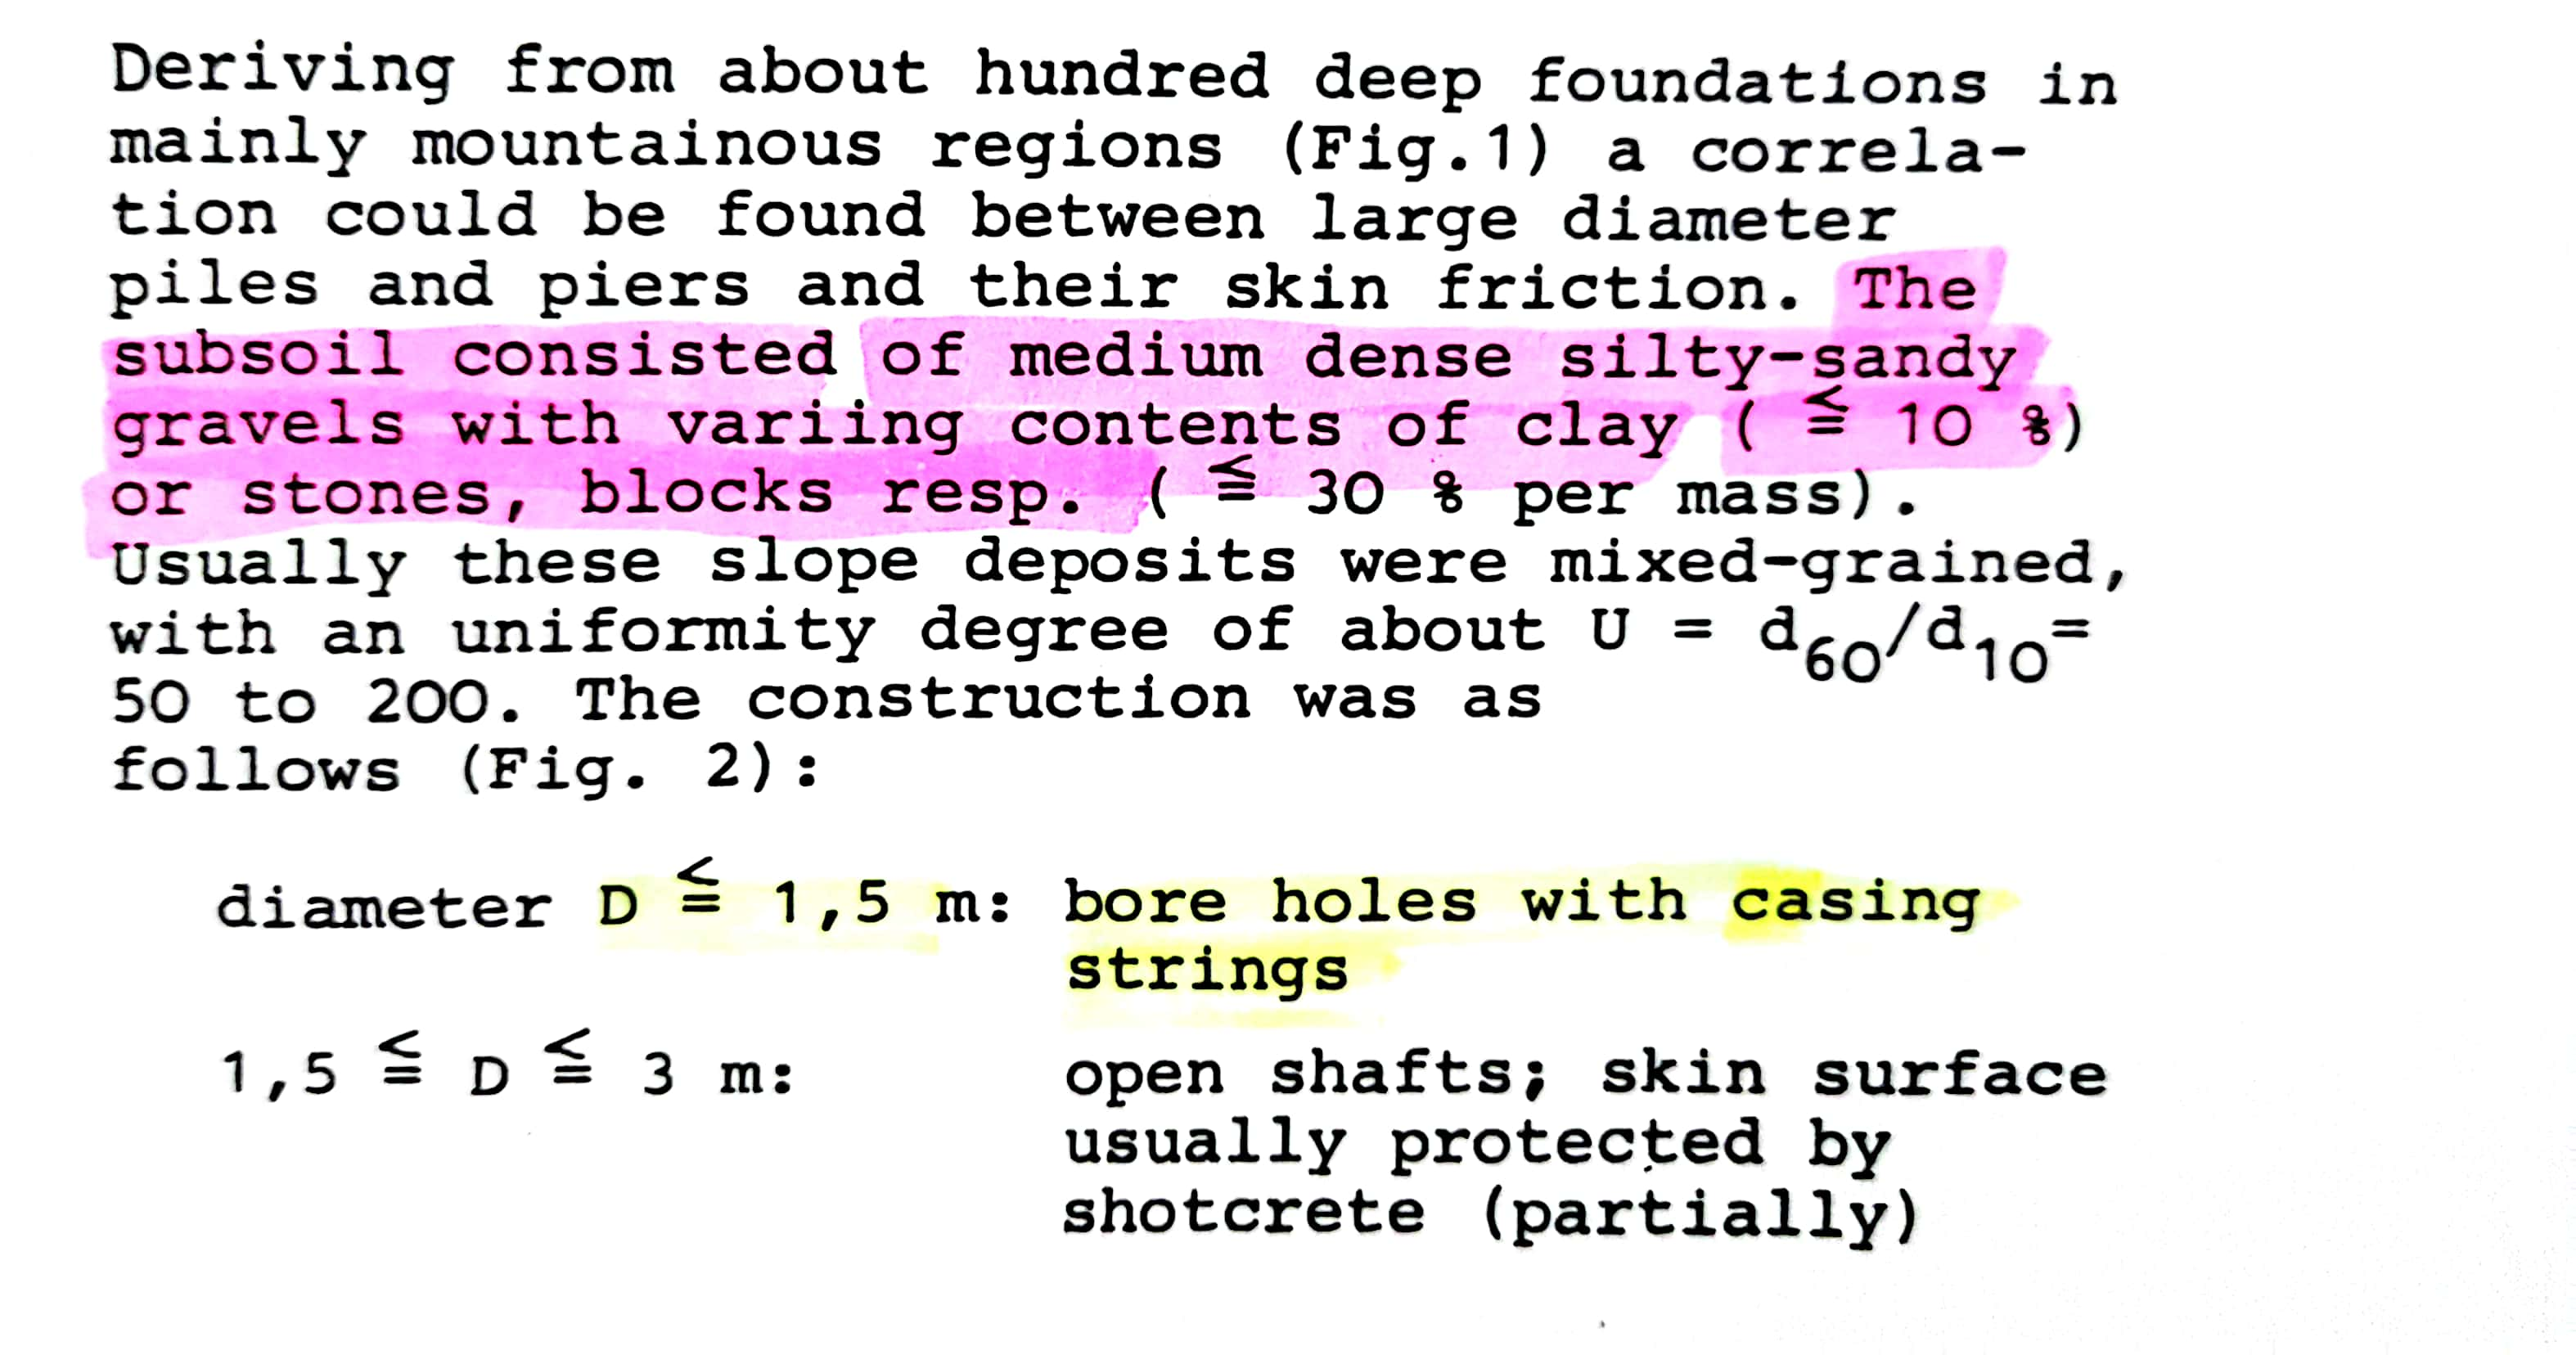

downloaded_graphs\14NzmqwWY5ipoORUOFxsvcbvvuKV-ZleM.png


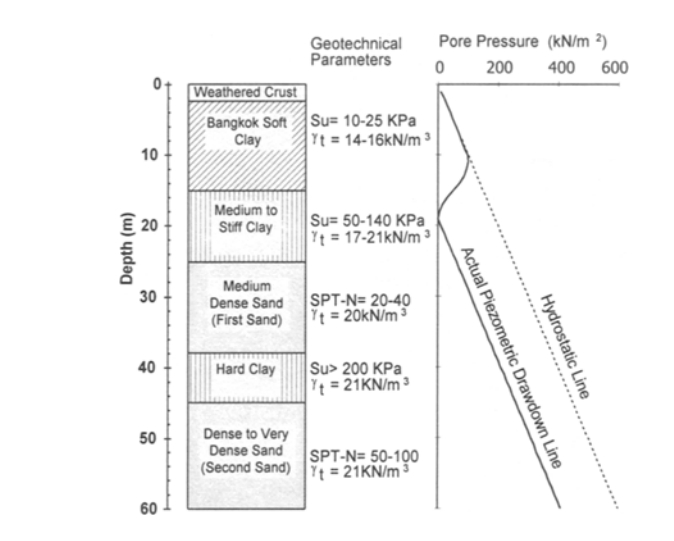

In [134]:
from IPython.display import Image, display
import glob

sample_imgs = sorted(glob.glob("downloaded_graphs/*.png"))[:3]
for img_path in sample_imgs:
    print(img_path)
    display(Image(filename=img_path, width=500))

In [135]:
cols = [c for c in ["site", "Location", "L", "B", "_file_id"] if c in df.columns]
display(df.loc[60:65, cols])
display(df.tail(3)[cols])

,site,Location,L,B,_file_id
60,DC40,Taiwan,50.0,1.50,NaN
61,UC1,"Saskatoon, Saskatchewan, Canada",5.5,0.61,1MOIbWVvMLc2y05-XLMy_TaRT358W1HfA
62,UC1,"Saskatoon, Saskatchewan, Canada",8.2,0.61,1MOIbWVvMLc2y05-XLMy_TaRT358W1HfA
63,UC2,"Munich, Germany",9.4,1.30,164EoyKDa19v0YZVeFDPjoR0nPhPHg_gl
64,UC3,"College Station, Texas, USA",1.8,0.18,1iR43obfM289FRY1T_inveHzIOFPY85CC
65,UC3,"College Station, Texas, USA",3.1,0.18,1iR43obfM289FRY1T_inveHzIOFPY85CC


,site,Location,L,B,_file_id
140,UC40,Taiwan,33.4,2.0,NaN
141,UC41,Taiwan,55.9,1.5,NaN
142,UC42,"Basra, Iraq",24.0,0.8,NaN


In [136]:
import json, os
if os.path.exists("extracted_profiles.json"):
    print("Saved so far:", len(json.load(open("extracted_profiles.json"))))

from google import genai
from google.genai import types, errors
from PIL import Image
from pydantic import BaseModel, Field

# 1. Initialize client without silent multi-attempt retries so 503s don't waste RPD quota
client = genai.Client(
    api_key=API_KEY,
    http_options=types.HttpOptions(
        retry_options=types.HttpRetryOptions(attempts=1)
    ),
)

# 2. Updated Schema with numeric depths and plotted-curve summaries
class SoilLayerData(BaseModel):
    top_depth_m: float = Field(description="Top depth of the soil layer in meters (e.g., 0.0)")
    bottom_depth_m: float = Field(description="Bottom depth of the soil layer in meters (e.g., 3.5)")
    soil_description: str = Field(description="Soil type or stratum description shown on the log")
    spt_n_representative: float | None = Field(default=None, description="Single representative or printed SPT N-value if explicitly given")
    spt_n_summary: str | None = Field(default=None, description="Approximate range or trend read from an SPT N scatter/profile plot for this depth interval (e.g., '10 to 25, increasing with depth')")
    cpt_qc_mpa_summary: str | None = Field(default=None, description="Approximate range or trend read from a CPT cone resistance (qc) plot in MPa for this depth interval (e.g., '2 to 8 MPa')")
    unit_weight_kn_m3: float | None = Field(default=None, description="Unit weight (gamma) in kN/m3 if shown")
    friction_angle_deg: float | None = Field(default=None, description="Friction angle (phi) in degrees if shown")
    undrained_shear_strength_kpa: float | None = Field(default=None, description="Undrained shear strength (su or cu) in kPa if shown")

class BoreholeExtraction(BaseModel):
    site_or_case_name: str | None = Field(default=None, description="Site name, project title, or test ID shown in the figure/caption")
    groundwater_depth_m: float | None = Field(default=None, description="Groundwater table depth in meters if indicated")
    layers: list[SoilLayerData] = Field(description="List of distinct soil strata ordered from top to bottom")
    additional_notes: str | None = Field(default=None, description="Other key soil index properties, grain size data, or plot notes")

# 3. Free-tier multimodal models with separate per-model daily quotas
FREE_TIER_MODELS = [
    "gemini-4-hydrogen",
    "gemini-3.6-flash",
    "gemini-3.5-flash-lite",
    "gemini-3.1-flash-lite",
]

OUTPUT_DIR = "extracted_json"
os.makedirs(OUTPUT_DIR, exist_ok=True)

EXTRACTION_PROMPT = (
    "Extract the geotechnical soil profile from this figure. "
    "Provide numeric top and bottom depths in meters for each distinct stratum, groundwater depth if marked, "
    "printed soil parameters, and approximate value ranges read directly from any plotted SPT N or CPT qc graphs across each layer."
)

def extract_with_fallback(image_path: str, active_models: list[str]):
    img = Image.open(image_path)
    for model_name in list(active_models):
        try:
            response = client.models.generate_content(
                model=model_name,
                contents=[img, EXTRACTION_PROMPT],
                config=types.GenerateContentConfig(
                    response_mime_type="application/json",
                    response_schema=BoreholeExtraction,
                ),
            )
            return json.loads(response.text), model_name
        except errors.ClientError as e:
            if e.code == 429:
                print(f"  [{model_name}] Daily/minute quota hit (429). Removing from active pool for this run...")
                active_models.remove(model_name)
                continue
            raise
        except errors.ServerError as e:
            if e.code in (500, 502, 503, 504):
                print(f"  [{model_name}] Server busy ({e.code}). Trying next model...")
                continue
            raise
    return None, None

# 4. Run batch extraction across all unique_ids with checkpointing
active_models = list(FREE_TIER_MODELS)
total = len(unique_ids)

for idx, file_id in enumerate(unique_ids, start=1):
    json_path = os.path.join(OUTPUT_DIR, f"{file_id}.json")
    
    # Skip if already extracted
    if os.path.exists(json_path):
        print(f"[{idx}/{total}] {file_id} -> Already cached, skipping.")
        continue

    img_path = os.path.join(IMAGE_DIR, f"{file_id}.png")
    if not os.path.exists(img_path):
        print(f"[{idx}/{total}] {file_id} -> Image missing, skipping.")
        continue

    if not active_models:
        print("\nAll free-tier model quotas exhausted for today. Re-run this exact cell later to resume from checkpoint.")
        break

    print(f"[{idx}/{total}] Extracting {file_id}...")
    data, used_model = extract_with_fallback(img_path, active_models)

    if data is not None:
        data["_file_id"] = file_id
        data["_model_used"] = used_model
        with open(json_path, "w", encoding="utf-8") as f:
            json.dump(data, f, indent=2)
        print(f"  Saved ({len(data.get('layers', []))} layers) via {used_model}")
        time.sleep(4.5)  # Respect per-minute RPM limits (~13 RPM)
    else:
        print(f"  Failed on {file_id} (all active models busy/exhausted).")

# 5. Flatten all saved JSON checkpoints into a clean layer-level DataFrame
rows = []
for file_id in unique_ids:
    json_path = os.path.join(OUTPUT_DIR, f"{file_id}.json")
    if not os.path.exists(json_path):
        continue
    with open(json_path, "r", encoding="utf-8") as f:
        doc = json.load(f)
    
    layers = doc.get("layers", [])
    if not layers:
        rows.append({
            "file_id": file_id,
            "site_or_case_name": doc.get("site_or_case_name"),
            "groundwater_depth_m": doc.get("groundwater_depth_m"),
            "layer_order": None,
            "additional_notes": doc.get("additional_notes"),
            "model_used": doc.get("_model_used"),
        })
    else:
        for layer_idx, layer in enumerate(layers, start=1):
            rows.append({
                "file_id": file_id,
                "site_or_case_name": doc.get("site_or_case_name"),
                "groundwater_depth_m": doc.get("groundwater_depth_m"),
                "layer_order": layer_idx,
                **layer,
                "additional_notes": doc.get("additional_notes"),
                "model_used": doc.get("_model_used"),
            })

df_extracted = pd.DataFrame(rows)
df_extracted.to_csv("extracted_soil_profiles.csv", index=False)
print(f"\nDone! Cached JSON files: {len(os.listdir(OUTPUT_DIR))}/{total} | Exported {len(df_extracted)} total soil layers to 'extracted_soil_profiles.csv'.")
display(df_extracted.head(10))

In [137]:
# Audit extracted_json for non-SI units (ft, tsf, ksf, bar, kg/cm2, psf, pcf)
audit_rows = []
for _, row in df.dropna(subset=["_file_id"]).drop_duplicates("_file_id").iterrows():
    fid = row["_file_id"]
    L_m = float(row["L"]) if pd.notna(row.get("L")) else np.nan
    path = os.path.join("extracted_json", f"{fid}.json")
    if not os.path.exists(path):
        continue
    with open(path, "r", encoding="utf-8") as f:
        doc = json.load(f)

    notes = str(doc.get("additional_notes") or "")
    layers = doc.get("layers", [])
    max_z = max([float(l["bottom_depth_m"]) for l in layers if l.get("bottom_depth_m") is not None] or [np.nan])
    qc_texts = [str(l.get("cpt_qc_mpa_summary")) for l in layers if l.get("cpt_qc_mpa_summary")]
    su_vals = [l.get("undrained_shear_strength_kpa") for l in layers if l.get("undrained_shear_strength_kpa") is not None]
    gam_vals = [l.get("unit_weight_kn_m3") for l in layers if l.get("unit_weight_kn_m3") is not None]

    # Flag suspicious unit mismatches
    flags = []
    if pd.notna(L_m) and pd.notna(max_z) and max_z > 2.2 * L_m and max_z > 30:
        flags.append(f"Depths likely ft (max_z={max_z} vs L={L_m}m)")
    if any(re.search(r"\b(tsf|ksf|bar|kg/cm|kpa|psf)\b", q.lower()) for q in qc_texts):
        flags.append(f"Non-MPa unit in qc: {qc_texts[:2]}")
    if any(re.search(r"\b(ft|feet|tsf|ksf|psf|pcf|bar|kg/cm)\b", notes.lower()) for _ in [0]):
        flags.append(f"Non-SI mention in notes: {notes[:80]}")
    if any(g < 10 or g > 30 for g in gam_vals):
        flags.append(f"Gamma out of kN/m3 range (likely pcf or g/cm3): {gam_vals}")

    if flags:
        audit_rows.append({"_file_id": fid, "L_m": L_m, "max_z": max_z, "flags": " | ".join(flags)})

print(f"Flagged {len(audit_rows)} files for unit conversion:")
display(pd.DataFrame(audit_rows))

Flagged 20 files for unit conversion:


,_file_id,L_m,max_z,flags
0,1yE-wi8zvgWXkjK_CnwDqGZKpBTHsGKqP,17.50,40.00,Depths likely ft (max_z=40.0 vs L=17.5m)
1,1BCp0K5WLyQHB3_p81VWtCCsBPsqmxHUY,18.30,200.00,Depths likely ft (max_z=200.0 vs L=18.3m)
2,1Lw5MtXvPkFV5x3_7fOh3CaCKU5J8b_0D,37.00,74.50,Non-SI mention in notes: Unit weights in the t...
3,1qmRhCj8DT4c3ixetydfEW6RoPjmKBxnR,6.40,18.29,Non-SI mention in notes: Depths in original fi...
4,1w6dB7QbB2SV7FcLf_6ey1lmGXHuGtEKB,10.00,12.20,Non-SI mention in notes: Depths converted usin...
5,1GyX43-LssyKG58tr-DTeAbm3Nsdy7ChF,12.00,104.50,Depths likely ft (max_z=104.5 vs L=12.0m)
6,1GNsTZVjl5QipvDNfO-PVfGTHsvOhU3do,12.20,457.20,Depths likely ft (max_z=457.2 vs L=12.2m) | No...
7,1zYy3hBKayQUeLLXoXigLgHzqdsge1Hvv,13.70,26.37,Non-SI mention in notes: Original depths in fe...
8,1rMJn85zYUxg5EKAAS_L6g6JH_M3xnDBj,26.50,27.74,Non-SI mention in notes: Depths in the origina...
9,1_YWeX1BMFdCaBG_CVHsK9YXpKEsQQpaE,12.60,25.91,Non-MPa unit in qc: ['0 to 300 tsf (0 to 28.7 ...


In [138]:
suspect_ids = [
    "1yE-wi8zvgWXkjK_CnwDqGZKpBTHsGKqP",  # row 0: max_z=40.0 vs L=17.5
    "1BCp0K5WLyQHB3_p81VWtCCsBPsqmxHUY",  # row 1: max_z=200.0 vs L=18.3
    "1Lw5MtXvPkFV5x3_7fOh3CaCKU5J8b_0D",  # row 2: unit weights in notes
    "1GyX43-LssyKG58tr-DTeAbm3Nsdy7ChF",  # row 5: max_z=104.5 vs L=12.0
    "1GNsTZVjl5QipvDNfO-PVfGTHsvOhU3do",  # row 6: max_z=457.2 vs L=12.2 (looks like 1500 ft or 45.72 m!)
    "1_YWeX1BMFdCaBG_CVHsK9YXpKEsQQpaE",  # row 9: 0 to 300 tsf (0 to 28.7 MPa)
    "1fMpDiZuZk-T4F5HJAmM9z3-uWSvO6R6o",  # row 10: 100 to 300 tsf
    "1w-_1caUrsA5HaRAB2jFQYZk5TFfmEz_1",  # row 12
    "1c9pnF8ASvFmhI5PXoJAUfNKM3RD4f_fB",  # row 14
    "1GaYSCIlk-xUZdlx5wueRBMNDwUXH-Mxt",  # row 15
]

for fid in suspect_ids:
    with open(os.path.join("extracted_json", f"{fid}.json"), "r", encoding="utf-8") as f:
        doc = json.load(f)
    print(f"=== {fid} | site={doc.get('site_or_case_name')} | gw={doc.get('groundwater_depth_m')} ===")
    print("Notes:", doc.get("additional_notes"))
    for lyr in doc.get("layers", []):
        print(" ", lyr)
    print()

=== 1yE-wi8zvgWXkjK_CnwDqGZKpBTHsGKqP | site=Glasgow Sheriffs Court Ground Conditions | gw=5.0 ===
Notes: Groundwater level indicated at 5m depth. SPT values increase significantly below 20m. CPT results provided for depths up to approximately 24m.
  {'top_depth_m': 0.0, 'bottom_depth_m': 3.0, 'soil_description': 'Fill', 'spt_n_summary': '10 to 30', 'cpt_qc_mpa_summary': '0 to 2 MPa'}
  {'top_depth_m': 3.0, 'bottom_depth_m': 33.0, 'soil_description': 'Silty fine & medium sand', 'spt_n_summary': '5 to 40, increasing with depth', 'cpt_qc_mpa_summary': '2 to 18 MPa, increasing with depth'}
  {'top_depth_m': 33.0, 'bottom_depth_m': 36.0, 'soil_description': 'Lodgement till', 'spt_n_summary': '40 to 65', 'cpt_qc_mpa_summary': None}
  {'top_depth_m': 36.0, 'bottom_depth_m': 40.0, 'soil_description': 'Lower Coal Measures (Rock)', 'spt_n_summary': '50 to 65', 'cpt_qc_mpa_summary': None}

=== 1BCp0K5WLyQHB3_p81VWtCCsBPsqmxHUY | site=Central Terminal Area at the airport | gw=1.5 ===
Notes: Layer

In [139]:
import re

OUTPUT_DIR = "extracted_json"

def parse_spt_summary(val, summary_str):
    """Use exact representative SPT N if present; otherwise take midpoint of range in summary text."""
    if pd.notna(val):
        return float(val)
    if isinstance(summary_str, str):
        nums = [float(x) for x in re.findall(r"[-+]?\d*\.\d+|\d+", summary_str)]
        if nums:
            return float(np.mean(nums[:2]))
    return np.nan

def parse_qc_mpa(summary_str):
    """Extract CPT qc midpoint in MPa, handling parenthesized MPa or converting tsf/ksf/bar/kgcm2/kPa."""
    if not isinstance(summary_str, str):
        return np.nan
    s = summary_str.lower()

    # 1. If Gemini already wrote an explicit MPa conversion in parentheses, e.g. "0 to 300 tsf (0 to 28.7 MPa)"
    mpa_match = re.search(r"\(([^)]*\bmpa\b[^)]*)\)", s)
    if mpa_match:
        nums = [float(x) for x in re.findall(r"[-+]?\d*\.\d+|\d+", mpa_match.group(1))]
        if nums:
            return float(np.mean(nums[:2]))

    # 2. Otherwise extract the primary numbers and convert based on unit
    nums = [float(x) for x in re.findall(r"[-+]?\d*\.\d+|\d+", s)]
    if not nums:
        return np.nan
    val = float(np.mean(nums[:2]))

    if re.search(r"\btsf\b", s):
        return val * 0.09576          # 1 tsf = 0.09576 MPa
    elif re.search(r"\bksf\b", s):
        return val * 0.04788          # 1 ksf = 0.04788 MPa
    elif re.search(r"\bbar\b", s):
        return val * 0.1              # 1 bar = 0.1 MPa
    elif "kg/cm" in s or "kgf/cm" in s:
        return val * 0.0980665        # 1 kgf/cm2 = 0.0980665 MPa
    elif re.search(r"\bkpa\b", s):
        return val / 1000.0           # 1 kPa = 0.001 MPa
    return val                        # Already in MPa

def normalize_gamma_kn_m3(val):
    if val is None or pd.isna(val):
        return np.nan
    g = float(val)
    if g > 40.0:                      # Likely pcf -> kN/m3
        return g * 0.157087
    elif 0 < g < 5.0:                 # Likely t/m3 or g/cm3 -> kN/m3
        return g * 9.80665
    return g

def compute_shaft_soil_features(row):
    file_id = row.get("_file_id")
    L = row.get("L (m)") if "L (m)" in row else row.get("L")
    B = row.get("B (m)") if "B (m)" in row else row.get("B")

    empty_result = pd.Series({
        "gw_depth_m": np.nan,
        "eff_stress_ratio_gw": np.nan,
        "n_layers_intersected": 0,
        "spt_n_shaft_avg": np.nan,
        "spt_n_tip": np.nan,
        "cpt_qc_shaft_avg_mpa": np.nan,
        "cpt_qc_tip_mpa": np.nan,
        "su_shaft_avg_kpa": np.nan,
        "su_tip_kpa": np.nan,
        "phi_shaft_avg_deg": np.nan,
        "phi_tip_deg": np.nan,
        "gamma_shaft_avg_kn_m3": np.nan,
        "dominant_shaft_soil": None,
        "tip_soil_description": None,
    })

    if pd.isna(file_id) or pd.isna(L):
        return empty_result

    json_path = os.path.join(OUTPUT_DIR, f"{file_id}.json")
    if not os.path.exists(json_path):
        return empty_result

    with open(json_path, "r", encoding="utf-8") as f:
        doc = json.load(f)

    gw = doc.get("groundwater_depth_m")
    layers = doc.get("layers", [])
    if not layers:
        empty_result["gw_depth_m"] = float(gw) if gw is not None else np.nan
        return empty_result

    L_val = float(L)
    half_zone = 1.5 * float(B) if pd.notna(B) else 1.0
    tip_top, tip_bot = max(0.0, L_val - half_zone), L_val + half_zone

    shaft_records = []
    tip_records = []

    for lyr in layers:
        z0_raw = lyr.get("top_depth_m")
        z1_raw = lyr.get("bottom_depth_m")
        if z1_raw is None:
            continue
        z0 = float(z0_raw) if z0_raw is not None else 0.0
        z1 = float(z1_raw)
        if z1 <= z0:
            continue

        spt = parse_spt_summary(lyr.get("spt_n_representative"), lyr.get("spt_n_summary"))
        qc = parse_qc_mpa(lyr.get("cpt_qc_mpa_summary"))
        su = float(lyr["undrained_shear_strength_kpa"]) if lyr.get("undrained_shear_strength_kpa") is not None else np.nan
        phi = float(lyr["friction_angle_deg"]) if lyr.get("friction_angle_deg") is not None else np.nan
        gamma = normalize_gamma_kn_m3(lyr.get("unit_weight_kn_m3"))
        desc = lyr.get("soil_description", "")

        ov_shaft = max(0.0, min(L_val, z1) - max(0.0, z0))
        if ov_shaft > 0:
            shaft_records.append((ov_shaft, spt, qc, su, phi, gamma, desc))

        ov_tip = max(0.0, min(tip_bot, z1) - max(0.0, tip_top))
        if ov_tip > 0:
            tip_records.append((ov_tip, spt, qc, su, phi, desc))

    def weighted_avg(records, col_idx):
        valid = [(r[0], r[col_idx]) for r in records if pd.notna(r[col_idx])]
        if not valid:
            return np.nan
        weights, vals = zip(*valid)
        return float(np.average(vals, weights=weights))

    dominant_shaft = max(shaft_records, key=lambda r: r[0])[6] if shaft_records else None
    tip_soil = max(tip_records, key=lambda r: r[0])[5] if tip_records else None

    submerged_ratio = (
        float(np.clip((L_val - float(gw)) / L_val, 0.0, 1.0))
        if (gw is not None and L_val > 0)
        else np.nan
    )

    return pd.Series({
        "gw_depth_m": float(gw) if gw is not None else np.nan,
        "eff_stress_ratio_gw": submerged_ratio,
        "n_layers_intersected": len(shaft_records),
        "spt_n_shaft_avg": weighted_avg(shaft_records, 1),
        "spt_n_tip": weighted_avg(tip_records, 1),
        "cpt_qc_shaft_avg_mpa": weighted_avg(shaft_records, 2),
        "cpt_qc_tip_mpa": weighted_avg(tip_records, 2),
        "su_shaft_avg_kpa": weighted_avg(shaft_records, 3),
        "su_tip_kpa": weighted_avg(tip_records, 3),
        "phi_shaft_avg_deg": weighted_avg(shaft_records, 4),
        "phi_tip_deg": weighted_avg(tip_records, 4),
        "gamma_shaft_avg_kn_m3": weighted_avg(shaft_records, 5),
        "dominant_shaft_soil": dominant_shaft,
        "tip_soil_description": tip_soil,
    })

# Apply to main DataFrame
soil_features = df.apply(compute_shaft_soil_features, axis=1)
df_enriched = pd.concat([df, soil_features], axis=1)

print("Enriched DataFrame shape:", df_enriched.shape)

site_col = "Site" if "Site" in df_enriched.columns else ("site" if "site" in df_enriched.columns else df_enriched.columns[0])
l_col = "L (m)" if "L (m)" in df_enriched.columns else "L"
b_col = "B (m)" if "B (m)" in df_enriched.columns else "B"

display(df_enriched[[site_col, l_col, b_col, "gw_depth_m", "spt_n_shaft_avg", "cpt_qc_shaft_avg_mpa", "su_shaft_avg_kpa", "dominant_shaft_soil"]].head(10))

Enriched DataFrame shape: (143, 61)


,site,L,B,gw_depth_m,spt_n_shaft_avg,cpt_qc_shaft_avg_mpa,su_shaft_avg_kpa,dominant_shaft_soil
0,DC1,17.5,0.60,5.0,22.071429,8.457143,NaN,Silty fine & medium sand
1,DC1,17.5,0.60,5.0,22.071429,8.457143,NaN,Silty fine & medium sand
2,DC1,16.0,0.60,5.0,22.031250,8.312500,NaN,Silty fine & medium sand
3,DC1,20.0,0.60,5.0,22.125000,8.650000,NaN,Silty fine & medium sand
4,DC1,17.5,0.60,5.0,22.071429,8.457143,NaN,Silty fine & medium sand
5,DC2,19.3,1.20,1.5,13.588083,6.424870,NaN,SILTY SAND
6,DC3,18.3,0.92,1.5,NaN,NaN,NaN,Glacial outwash sands of varying gradation and...
7,DC4,5.0,0.24,NaN,NaN,NaN,NaN,"Uniform, compact sand (85% sand, 15% gravel)"
8,DC5,21.5,0.96,NaN,NaN,NaN,NaN,NaN
9,DC6,11.0,0.90,NaN,NaN,NaN,NaN,NaN


In [140]:
df_enriched

,Reference,Location,GW_depth,Depth(m),Soil Profile,Soil Property,UCSC Classification,Gravel,Sand,Clay,...,spt_n_tip,cpt_qc_shaft_avg_mpa,cpt_qc_tip_mpa,su_shaft_avg_kpa,su_tip_kpa,phi_shaft_avg_deg,phi_tip_deg,gamma_shaft_avg_kn_m3,dominant_shaft_soil,tip_soil_description
0,DC1-1,"Glasgow, UK",6.0,17.5,Silty fine & medium sand,DC1-1,SW-SM,0.0,100.0,0.0,...,44.166667,8.457143,10.0,NaN,NaN,NaN,NaN,NaN,Silty fine & medium sand,Silty fine & medium sand
1,DC1-2,"Glasgow, UK",6.0,17.5,Silty fine & medium sand,DC1-2,SW-SM,0.0,100.0,0.0,...,44.166667,8.457143,10.0,NaN,NaN,NaN,NaN,NaN,Silty fine & medium sand,Silty fine & medium sand
2,DC1-3,"Glasgow, UK",6.0,16.0,Silty fine & medium sand,DC1-3,SW-SM,0.0,100.0,0.0,...,44.166667,8.312500,10.0,NaN,NaN,NaN,NaN,NaN,Silty fine & medium sand,Silty fine & medium sand
3,DC1-4,"Glasgow, UK",6.0,20.0,Silty fine & medium sand,DC1-4,SW-SM,0.0,100.0,0.0,...,44.166667,8.650000,10.0,NaN,NaN,NaN,NaN,NaN,Silty fine & medium sand,Silty fine & medium sand
4,DC1-5,"Glasgow, UK",6.0,17.5,Silty fine & medium sand,DC1-5,SW-SM,0.0,100.0,0.0,...,44.166667,8.457143,10.0,NaN,NaN,NaN,NaN,NaN,Silty fine & medium sand,Silty fine & medium sand
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138,UC38,"Houston-Gulf, Texas, USA",1.4,18.9,Stiff Beaumont clay formation,NaN,NaN,0.0,5.0,95.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
139,UC39,"Bangkok, Thailand",1.0,57.5,"Soft, hard clay and dense sand",NaN,NaN,0.0,23.0,77.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,UC40,Taiwan,NaN,33.4,"Sand, clay and gravel",NaN,NaN,28.0,14.0,58.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
141,UC41,Taiwan,NaN,55.9,"Sand, clay and debris",NaN,NaN,18.0,5.0,77.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


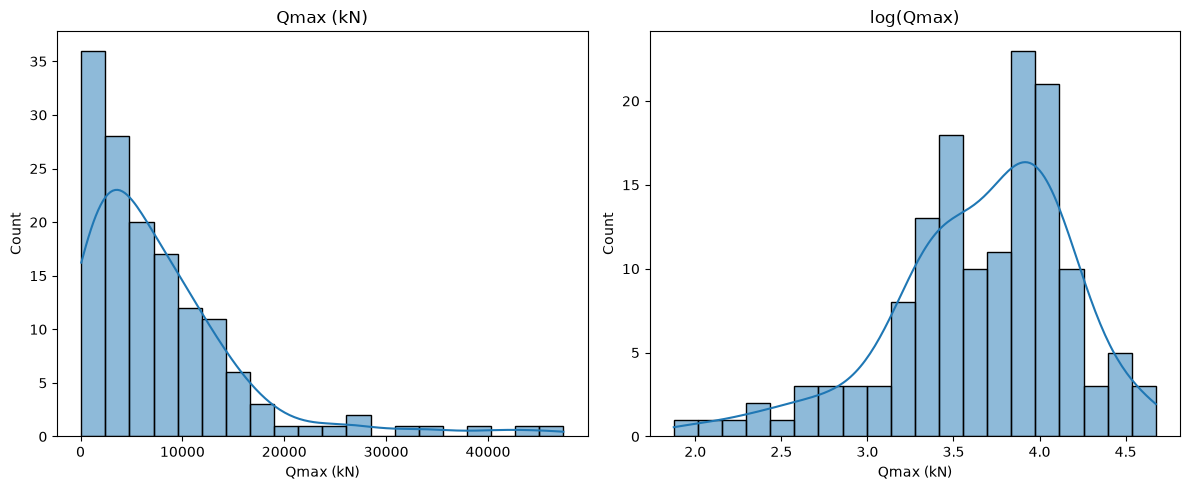

Skewness Qmax (kN): 2.359
Skewness log(Qmax): -0.859


In [141]:
log_qmax = np.log10(df["Qmax (kN)"])  
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["Qmax (kN)"], bins=20, kde=True, ax=ax[0])
ax[0].set_title("Qmax (kN)")

sns.histplot(log_qmax, bins=20, kde=True, ax=ax[1])
ax[1].set_title("log(Qmax)")

plt.tight_layout()
plt.show()
print(f"Skewness Qmax (kN): {df['Qmax (kN)'].skew():.3f}")
print(f"Skewness log(Qmax): {log_qmax.skew():.3f}")

If Qmax represents total measured capacity, 
dividing by shaft surface area does not produce pure unit shaft resistance because the measured capacity may include end-bearing resistance.
I will call it as 'Normalized pile resistance (kPa)'

In [142]:
df['Normalized pile resistance (kPa)']=df['Qmax (kN)'] / (np.pi * df['B'] * df['L'])

#log_NPR=lof of Normalized pile resistance (kPa)

In [143]:
df['log_NPR'] = np.log(df['Normalized pile resistance (kPa)'])

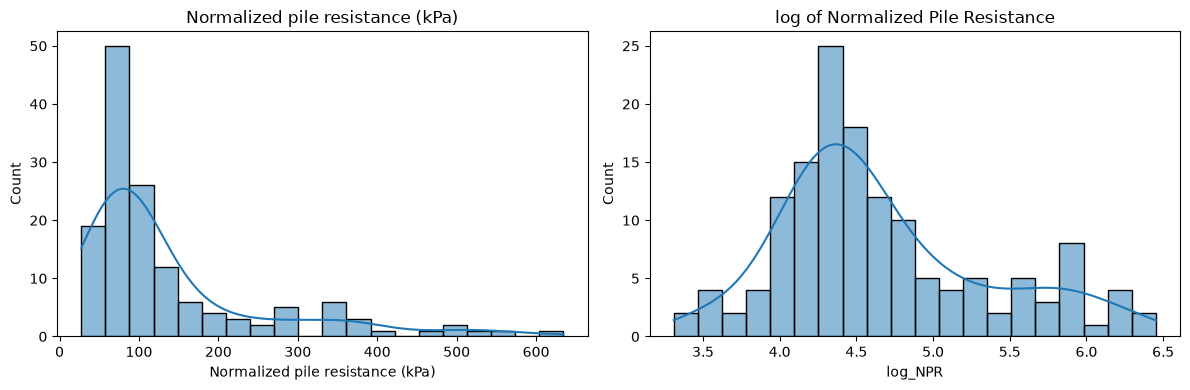

Skewness Normalized pile resistance (kPa): 2.039
Skewness log of Normalized Pile Resistance: 0.772


In [144]:
# Compare distributions of log(Qmax) vs log(q_area)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Normalized pile resistance (kPa)'], bins=20, kde=True, ax=ax[0])
ax[0].set_title('Normalized pile resistance (kPa)')
sns.histplot(df['log_NPR'], bins=20, kde=True, ax=ax[1])
ax[1].set_title('log of Normalized Pile Resistance')
plt.tight_layout()
plt.show()
print(f"Skewness Normalized pile resistance (kPa): {df['Normalized pile resistance (kPa)'].skew():.3f}")
print(f"Skewness log of Normalized Pile Resistance: {df['log_NPR'].skew():.3f}")


In [145]:
# 1. Backfill missing cells in your existing Excel columns using the extracted SI JSON values
backfill_map = {
    'GW_depth': 'gw_depth_m',
    'Unit Weight,γt (kN/m3)': 'gamma_shaft_avg_kn_m3',
    'Friction Angle(ϕ (deg))': 'phi_shaft_avg_deg',
    'Undrained Shear Strength(su (kPa))': 'su_shaft_avg_kpa',
    'SPT_N': 'spt_n_shaft_avg',
}

for orig_col, json_col in backfill_map.items():
    if orig_col in df.columns and json_col in df_enriched.columns:
        df[orig_col] = pd.to_numeric(df[orig_col], errors='coerce')
        before_na = df[orig_col].isna().sum()
        df[orig_col] = df[orig_col].fillna(df_enriched[json_col])
        after_na = df[orig_col].isna().sum()
        print(f"{orig_col}: filled {before_na - after_na} missing values (remaining NaN: {after_na})")

# 2. Add new physics-informed columns from df_enriched that aren't in your original Excel sheet
new_json_cols = [
    'eff_stress_ratio_gw',
    'spt_n_tip',
    'su_tip_kpa',
    'phi_tip_deg',
    'cpt_qc_shaft_avg_mpa',
    'cpt_qc_tip_mpa',
    'dominant_shaft_soil',
    'tip_soil_description',
]

for col in new_json_cols:
    if col in df_enriched.columns:
        df[col] = df_enriched[col]

GW_depth: filled 1 missing values (remaining NaN: 33)
Unit Weight,γt (kN/m3): filled 1 missing values (remaining NaN: 85)
Friction Angle(ϕ (deg)): filled 0 missing values (remaining NaN: 48)
Undrained Shear Strength(su (kPa)): filled 3 missing values (remaining NaN: 61)
SPT_N: filled 1 missing values (remaining NaN: 3)


In [146]:
exclude_sites = ['DC12', 'DC6', 'DC38', 'DC16']
json_cols = ['eff_stress_ratio_gw','spt_n_tip','su_tip_kpa','phi_tip_deg',
             'cpt_qc_shaft_avg_mpa','cpt_qc_tip_mpa','dominant_shaft_soil','tip_soil_description']
json_cols = [c for c in json_cols if c in df.columns]
df.loc[df['site'].isin(exclude_sites), json_cols] = np.nan

# Cap SPT-N at 100 (refusal convention)
for c in ['SPT_N', 'spt_n_tip']:
    if c in df.columns:
        df[c] = df[c].clip(upper=100)

# Groundwater relative to pile length (computed once, before clipping)
if 'gw_over_L' not in df.columns:
    df['gw_over_L'] = df['GW_depth'] / df['L']
df['GW_depth'] = df['GW_depth'].clip(upper=50)

print("SPT_N max:", df['SPT_N'].max())
print(df.loc[df['site'].isin(exclude_sites), ['site'] + json_cols[:3]].head(6))

SPT_N max: 100.0
    site  eff_stress_ratio_gw  spt_n_tip  su_tip_kpa
9    DC6                  NaN        NaN         NaN
17  DC12                  NaN        NaN         NaN
23  DC16                  NaN        NaN         NaN
58  DC38                  NaN        NaN         NaN


In [147]:
# Combine original numerical features with the newly extracted tip/CPT/GW-ratio features
extended_numerical_features = [
    'L', 'B', 'L_B', 'GW_depth', 'eff_stress_ratio_gw',
    'Gravel', 'Sand', 'Clay',
    'Unit Weight,γt (kN/m3)', 'Relative Density,Dr (%)',
    "Vertical Effective Stress(σv' (kPa))",
    'Friction Angle(ϕ (deg))', 'phi_tip_deg',
    'Undrained Shear Strength(su (kPa))', 'su_tip_kpa',
    'SPT_N', 'spt_n_tip',
    'cpt_qc_shaft_avg_mpa', 'cpt_qc_tip_mpa'
]

# Keep only features present in df with numeric dtypes
extended_numerical_features = [
    c for c in extended_numerical_features 
    if c in df.columns and pd.api.types.is_numeric_dtype(df[c])
]

print(df[extended_numerical_features].dtypes)

corr_qmax = df[extended_numerical_features + ['Qmax (kN)']].corr()['Qmax (kN)'].sort_values(ascending=False)
corr_qarea = df[extended_numerical_features + ['Normalized pile resistance (kPa)']].corr()['Normalized pile resistance (kPa)'].sort_values(ascending=False)

corr_summary = pd.DataFrame({
    'correlation wrt Qmax(kN)': corr_qmax,
    'correlation wrt normalized pile resistance (kpa)': corr_qarea,
    'non_null_count': df[extended_numerical_features + ['Qmax (kN)', 'Normalized pile resistance (kPa)']].notna().sum()
})

display(corr_summary.sort_values(by='correlation wrt normalized pile resistance (kpa)', ascending=False))

L                                       float64
B                                       float64
L_B                                     float64
GW_depth                                float64
eff_stress_ratio_gw                     float64
Gravel                                  float64
Sand                                    float64
Clay                                    float64
Unit Weight,γt (kN/m3)                  float64
Relative Density,Dr (%)                 float64
Vertical Effective Stress(σv' (kPa))    float64
Friction Angle(ϕ (deg))                 float64
phi_tip_deg                             float64
Undrained Shear Strength(su (kPa))      float64
su_tip_kpa                              float64
SPT_N                                   float64
spt_n_tip                               float64
cpt_qc_shaft_avg_mpa                    float64
cpt_qc_tip_mpa                          float64
dtype: object


,correlation wrt Qmax(kN),correlation wrt normalized pile resistance (kpa),non_null_count
Normalized pile resistance (kPa),NaN,1.000000,143
"Unit Weight,γt (kN/m3)",-0.053844,0.425319,58
Undrained Shear Strength(su (kPa)),0.038950,0.394853,82
cpt_qc_tip_mpa,-0.041556,0.256661,12
SPT_N,0.168912,0.236166,140
"Relative Density,Dr (%)",0.379911,0.223182,59
Friction Angle(ϕ (deg)),0.234466,0.188801,95
GW_depth,-0.130235,0.180899,110
cpt_qc_shaft_avg_mpa,-0.088053,0.112721,12
eff_stress_ratio_gw,0.459858,0.096869,22


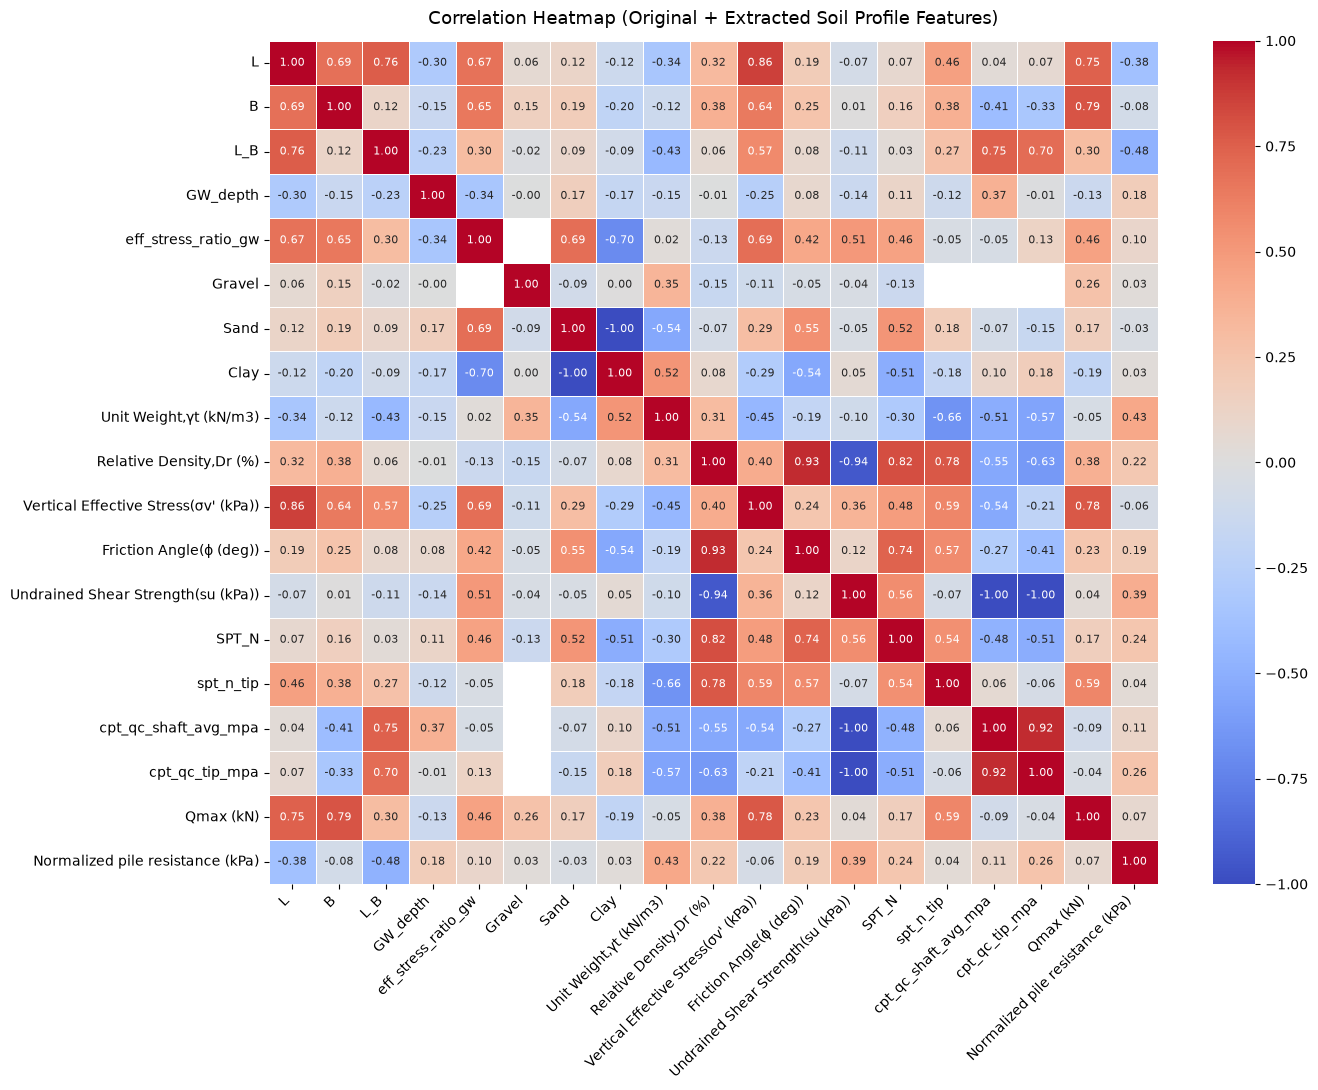

In [148]:
# 1. Define expanded feature list (original + newly extracted shaft/tip features)
candidate_cols = [
    'L', 'B', 'L_B',
    'GW_depth', 'eff_stress_ratio_gw',
    'Gravel', 'Sand', 'Clay',
    'Unit Weight,γt (kN/m3)', 'Relative Density,Dr (%)',
    "Vertical Effective Stress(σv' (kPa))",
    'Friction Angle(ϕ (deg))', 'phi_tip_deg',
    'Undrained Shear Strength(su (kPa))', 'su_tip_kpa',
    'SPT_N', 'spt_n_tip',
    'cpt_qc_shaft_avg_mpa', 'cpt_qc_tip_mpa',
    'Qmax (kN)', 'Normalized pile resistance (kPa)'
]

# Keep columns that exist in df and have at least 10 non-null observations
cols = [c for c in candidate_cols if c in df.columns and df[c].notna().sum() >= 10]

# 2. Plot scaled correlation heatmap
plt.figure(figsize=(14, 11))
corr_matrix = df[cols].corr()

sns.heatmap(
    corr_matrix,
    fmt=".2f",
    annot=True,
    annot_kws={"size": 8},
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    linewidths=0.5
)
plt.title("Correlation Heatmap (Original + Extracted Soil Profile Features)", fontsize=13, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [149]:
# Check current counts first
print("Before backfill:\n", df['soil_class'].value_counts(dropna=False), "\n")

# Classify extracted dominant_shaft_soil text (supporting both full names and USCS codes like SP, SW, CL, CH, ML)
def classify_from_text(desc):
    if not isinstance(desc, str) or not desc.strip():
        return np.nan
    s = desc.lower()
    has_sand = (
        any(k in s for k in ['sand', 'gravel', 'silt', 'till', 'loam'])
        or bool(re.search(r'\b(sw|sp|sm|sc|gw|gp|gm|gc|ml|mh)\b', s))
    )
    has_clay = (
        any(k in s for k in ['clay', 'mud', 'shale', 'cohesive'])
        or bool(re.search(r'\b(cl|ch|ol|oh)\b', s))
    )
    if has_sand and not has_clay:
        return 'Sand'   # Update if your existing label is 'Cohesionless'
    elif has_clay and not has_sand:
        return 'Clay'   # Update if your existing label is 'Cohesive'
    elif has_sand and has_clay:
        return 'Mixed'
    return np.nan

# Preview where extracted JSON text can fill missing/Unknown soil_class rows
inferred_class = df_enriched['dominant_shaft_soil'].apply(classify_from_text)
missing_mask = df['soil_class'].isna() | df['soil_class'].isin(['Unknown', 'Other', ''])

print(f"Rows eligible for soil_class backfill: {missing_mask.sum()}")
site_col = 'site' if 'site' in df.columns else ('Site' if 'Site' in df.columns else df.columns[0])
display(pd.DataFrame({
    'site': df.loc[missing_mask, site_col],
    'current_soil_class': df.loc[missing_mask, 'soil_class'],
    'dominant_shaft_soil': df_enriched.loc[missing_mask, 'dominant_shaft_soil'],
    'inferred_class': inferred_class[missing_mask]
}))

Before backfill:
 soil_class
Fine-grained (Clay/Silt)        70
Coarse-grained (Sand/Gravel)    58
Mixed / Borderline               9
Cemented / Rock                  6
Name: count, dtype: int64 

Rows eligible for soil_class backfill: 0


,site,current_soil_class,dominant_shaft_soil,inferred_class


In [150]:
summary = df.groupby('soil_class')['Normalized pile resistance (kPa)'].agg(['mean', 'median', 'min', 'max'])
print(summary.sort_values('median', ascending=False))

                                    mean      median         min         max
soil_class                                                                  
Cemented / Rock               329.334120  345.257054  188.472959  467.547734
Coarse-grained (Sand/Gravel)  134.112677   88.265107   27.374650  634.345202
Fine-grained (Clay/Silt)      131.667090   86.564088   34.665664  562.196138
Mixed / Borderline             84.541995   78.781697   44.150021  127.897016


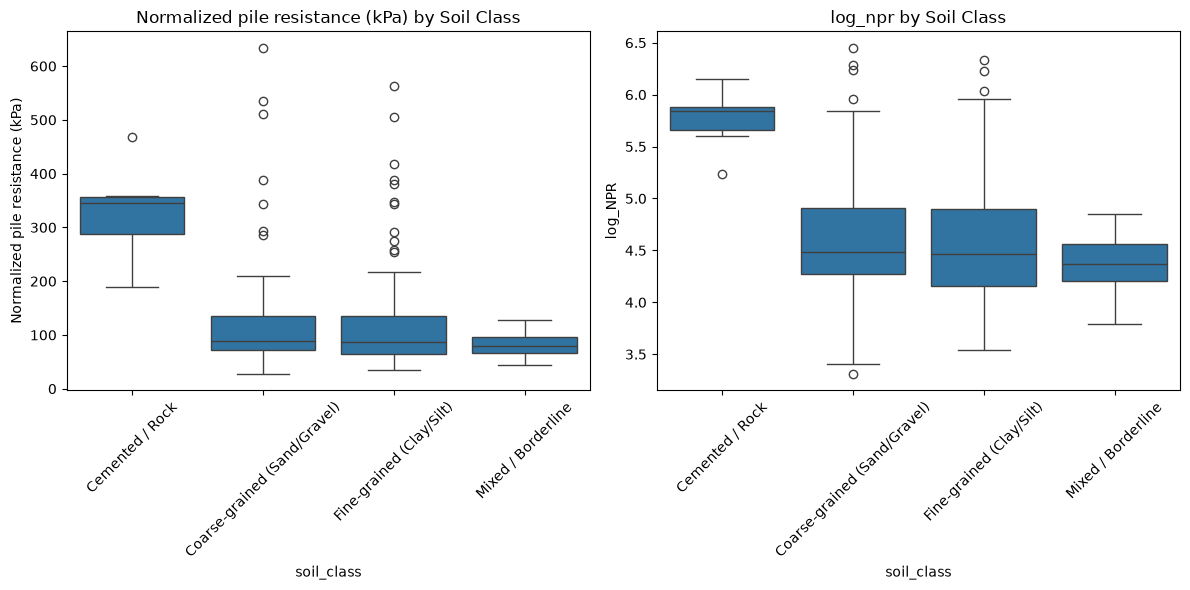

In [151]:
order = (df.groupby('soil_class')['Normalized pile resistance (kPa)'].median().sort_values(ascending=False).index)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

sns.boxplot(data=df, x='soil_class', y='Normalized pile resistance (kPa)', order=order, ax=ax[0])
ax[0].set_title('Normalized pile resistance (kPa) by Soil Class')
ax[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='soil_class', y='log_NPR', order=order, ax=ax[1])
ax[1].set_title('log_npr by Soil Class')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [152]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [153]:

# 1. Define enriched numerical & categorical features
candidate_num = [
    'L', 'B', 'L_B',
    'GW_depth', 'eff_stress_ratio_gw',
    'Gravel', 'Sand', 'Clay',
    'Unit Weight,γt (kN/m3)', 'Relative Density,Dr (%)',
    "Vertical Effective Stress(σv' (kPa))",
    'Friction Angle(ϕ (deg))', 'phi_tip_deg',
    'Undrained Shear Strength(su (kPa))', 'su_tip_kpa',
    'SPT_N', 'spt_n_tip',
    'cpt_qc_shaft_avg_mpa', 'cpt_qc_tip_mpa',
]

# Keep numeric columns with at least 40% non-null data so median imputation doesn't distort PCA
min_valid = int(0.4 * len(df))
enriched_num_features = [
    c for c in candidate_num
    if c in df.columns and pd.api.types.is_numeric_dtype(df[c]) and df[c].notna().sum() >= min_valid
]

enriched_cat_features = [
    c for c in ['soil_class', 'tip_soil_class', 'gradation', 'Constr']
    if c in df.columns
]

X_enriched = df[enriched_num_features + enriched_cat_features].copy()

# Ensure log_NPR exists for bubble sizing
if 'log_NPR' not in df.columns:
    df['log_NPR'] = np.log(df['Normalized pile resistance (kPa)'])


In [154]:

# 2. Build preprocessing + PCA pipeline
numerical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipe, enriched_num_features),
    ('cat', categorical_pipe, enriched_cat_features),
])

pca_pipeline = Pipeline([
    ('prep', preprocessor),
    ('pca', PCA(n_components=None, random_state=42)),
])

X_pca = pca_pipeline.fit_transform(X_enriched)
pca = pca_pipeline.named_steps['pca']


In [155]:
# Normalize any short labels ('Sand'/'Clay'/'Mixed') to match your primary soil_class taxonomy
soil_label_map = {
    'Sand': 'Coarse-grained (Sand/Gravel)',
    'Clay': 'Fine-grained (Clay/Silt)',
    'Mixed': 'Mixed / Borderline',
}
soil_series = df['soil_class'].replace(soil_label_map).fillna('Unknown')
site_col = 'site' if 'site' in df.columns else ('Site' if 'Site' in df.columns else df.columns[0])

# 3. Build plotting DataFrame from enriched df
pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Reference': df['Reference'].fillna('N/A').values if 'Reference' in df.columns else ['N/A'] * len(df),
    'site': df[site_col].fillna('N/A').values,
    'soil_class': soil_series.values,
    'gradation': df['gradation'].fillna('N/A').values if 'gradation' in df.columns else ['N/A'] * len(df),
    'q_max': df['Normalized pile resistance (kPa)'].values,
    'log_qmax': df['log_NPR'].values,
    'L': df['L'].values,
    'B': df['B'].values,
    'SPT_N': df['SPT_N'].values,
    'spt_n_tip': df['spt_n_tip'].values if 'spt_n_tip' in df.columns else np.full(len(df), np.nan),
})

# 4. Create 1x2 interactive subplot layout
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        'PCA Explained Variance Ratio (Enriched Features)',
        'PC1 vs PC2 by Soil Class (Size = log_NPR)',
    ),
)

# Left Plot: Interactive Scree Plot
pcs = list(range(1, len(pca.explained_variance_ratio_) + 1))
ind_var = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(ind_var)

fig.add_trace(
    go.Bar(
        x=pcs,
        y=ind_var,
        name='Individual Var (%)',
        marker_color='steelblue',
        opacity=0.65,
        hovertemplate='PC%{x}<br>Individual: %{y:.2f}%<extra></extra>',
    ),
    row=1, col=1,
)

fig.add_trace(
    go.Scatter(
        x=pcs,
        y=cum_var,
        mode='lines+markers',
        name='Cumulative Var (%)',
        line=dict(color='darkred', width=2),
        customdata=ind_var,
        hovertemplate=(
            '<b>Components kept: %{x}</b> (PC1 to PC%{x})<br>'
            + 'Cumulative Variance: <b>%{y:.2f}%</b><br>'
            + 'This PC alone adds: %{customdata:.2f}%'
            + '<extra></extra>'
        ),
    ),
    row=1, col=1,
)

fig.add_hline(
    y=80,
    line_dash='dash',
    line_color='gray',
    annotation_text='80% Threshold',
    annotation_position='bottom right',
    row=1, col=1,
)

# Right Plot: Interactive PC1 vs PC2 Scatter Plot
colors = {
    'Coarse-grained (Sand/Gravel)': '#1f77b4',
    'Fine-grained (Clay/Silt)': '#98a02c',
    'Mixed / Borderline': '#ff7f0e',
    'Cemented / Rock': '#100101',
}

q_min, q_max_val = pca_df['log_qmax'].min(), pca_df['log_qmax'].max()
pca_df['marker_size'] = (
    7 + 15 * (pca_df['log_qmax'] - q_min) / (q_max_val - q_min)
).fillna(10)

for s_class, group in pca_df.groupby('soil_class'):
    custom_data = np.stack(
        [
            group['Reference'],
            group['site'],
            group['gradation'],
            group['q_max'],
            group['log_qmax'],
            group['L'],
            group['B'],
            group['SPT_N'],
            group['spt_n_tip'],
        ],
        axis=-1,
    )

    fig.add_trace(
        go.Scatter(
            x=group['PC1'],
            y=group['PC2'],
            mode='markers',
            name=s_class,
            marker=dict(
                size=group['marker_size'],
                color=colors.get(s_class, '#7f7f7f'),
                opacity=0.85,
                line=dict(width=0.8, color='white'),
            ),
            customdata=custom_data,
            hovertemplate=(
                '<b>%{customdata[0]}</b> (Site: %{customdata[1]})<br>'
                + f'Soil: {s_class} | Gradation: %{{customdata[2]}}<br>'
                + 'PC1: %{x:.2f} | PC2: %{y:.2f}<br>'
                + 'NPR: %{customdata[3]:.1f} kPa (log: %{customdata[4]:.2f})<br>'
                + 'L: %{customdata[5]:.2f} m | B: %{customdata[6]:.2f} m<br>'
                + 'SPT_N (shaft): %{customdata[7]:.1f} | SPT_N (tip): %{customdata[8]:.1f}'
                + '<extra></extra>'
            ),
        ),
        row=1, col=2,
    )

# 5. Axis labels & layout styling
fig.update_xaxes(title_text='Principal Component', row=1, col=1)
fig.update_yaxes(title_text='Explained Variance (%)', range=[0, 105], row=1, col=1)

fig.update_xaxes(
    title_text=f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)',
    row=1, col=2,
)
fig.update_yaxes(
    title_text=f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)',
    row=1, col=2,
)

fig.update_layout(
    height=520,
    width=1150,
    template='plotly_white',
    legend=dict(title='Legend (Click to toggle)', x=1.02, y=1),
    margin=dict(t=60, b=50, l=50, r=180),
)

fig.show()

In [156]:
# 1. Extract clean feature names from the enriched ColumnTransformer
raw_names = pca_pipeline.named_steps['prep'].get_feature_names_out()
clean_names = [name.replace('num__', '').replace('cat__', '') for name in raw_names]

# 2. Build loadings DataFrame for PC1, PC2, and PC3
loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=['PC1_weight', 'PC2_weight', 'PC3_weight'],
    index=clean_names,
)

# 3. Sort by strongest absolute contribution to PC1 (and inspect PC2's top drivers separately)
print("Top Feature Loadings Sorted by |PC1| ")
display(loadings.reindex(loadings['PC1_weight'].abs().sort_values(ascending=False).index).round(3))

print("\nTop 8 Feature Loadings Sorted by |PC2|")
display(loadings.reindex(loadings['PC2_weight'].abs().sort_values(ascending=False).index).head(8).round(3))

Top Feature Loadings Sorted by |PC1| 


,PC1_weight,PC2_weight,PC3_weight
Sand,0.469,-0.193,-0.182
Clay,-0.466,0.186,0.184
Friction Angle(ϕ (deg)),0.377,-0.035,0.364
SPT_N,0.377,-0.061,0.411
"Unit Weight,γt (kN/m3)",-0.239,0.007,0.298
soil_class_Coarse-grained (Sand/Gravel),0.211,-0.109,-0.072
B,0.197,0.406,0.064
soil_class_Fine-grained (Clay/Silt),-0.195,0.102,0.043
L,0.190,0.594,-0.145
Constr_Dry,-0.148,-0.096,-0.020



Top 8 Feature Loadings Sorted by |PC2|


,PC1_weight,PC2_weight,PC3_weight
L,0.190,0.594,-0.145
L_B,0.145,0.448,-0.261
B,0.197,0.406,0.064
GW_depth,0.056,-0.308,0.043
"Relative Density,Dr (%)",0.047,0.239,0.616
Sand,0.469,-0.193,-0.182
Clay,-0.466,0.186,0.184
soil_class_Coarse-grained (Sand/Gravel),0.211,-0.109,-0.072
